Irfan Ali Task

In [1]:
!pip -q install -U ultralytics

In [2]:
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
from base64 import b64decode
from IPython.display import display, Javascript
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow
from ultralytics import YOLO
from ultralytics.utils import ASSETS   # sample images shipped with ultralytics

print("OpenCV version:", cv2.__version__)
print("Setup complete")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
OpenCV version: 5.0.0
Setup complete


In [3]:
CAPTURE_JS = '''
async function captureFrames(n, delayMs, quality) {
  const div = document.createElement('div');
  const video = document.createElement('video');
  video.style.display = 'block';
  video.style.maxWidth = '320px';
  div.appendChild(video);
  document.body.appendChild(div);
  const stream = await navigator.mediaDevices.getUserMedia({video: true});
  video.srcObject = stream;
  await video.play();
  google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
  await new Promise(r => setTimeout(r, 1000));
  const canvas = document.createElement('canvas');
  canvas.width = video.videoWidth;
  canvas.height = video.videoHeight;
  const ctx = canvas.getContext('2d');
  const frames = [];
  for (let i = 0; i < n; i++) {
    ctx.drawImage(video, 0, 0);
    frames.push(canvas.toDataURL('image/jpeg', quality));
    await new Promise(r => setTimeout(r, delayMs));
  }
  stream.getVideoTracks()[0].stop();
  div.remove();
  return frames;
}
'''

def decode_frame(data_url):
    raw = b64decode(data_url.split(",")[1])
    return cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)

def get_frames(n=1, delay_ms=200, quality=0.7):
    '''Capture n frames from the browser webcam. Returns a list of BGR frames or None.'''
    try:
        display(Javascript(CAPTURE_JS))
        data = eval_js(f"captureFrames({int(n)}, {int(delay_ms)}, {float(quality)})")
        frames = [decode_frame(d) for d in data]
        frames = [f for f in frames if f is not None]
        return frames if frames else None
    except Exception as e:
        print("Camera not available:", e)
        return None

def show(img, max_width=800):
    '''Display an OpenCV image in Colab, resized to fit.'''
    h, w = img.shape[:2]
    if w > max_width:
        img = cv2.resize(img, (max_width, int(h * max_width / w)))
    cv2_imshow(img)

def sample_image():
    img = cv2.imread(str(ASSETS / "bus.jpg"))
    if img is None:
        img = np.full((480, 640, 3), 90, np.uint8)
    return img

def synthetic_frames(n=40):
    '''Fake video (a box moving over a static background) used when no camera exists.'''
    frames = []
    for i in range(n):
        f = np.full((480, 640, 3), 60, np.uint8)
        if i >= 12:
            x = 30 + (i - 12) * 15
            cv2.rectangle(f, (x, 190), (x + 130, 330), (200, 120, 40), -1)
        frames.append(f)
    return frames

print("Helpers ready")

Helpers ready


Capturing one frame... allow the camera in your browser.


<IPython.core.display.Javascript object>

Camera not available: NotAllowedError: Permission denied
Using a sample image instead.
Frame shape (height, width, channels): (1080, 810, 3)


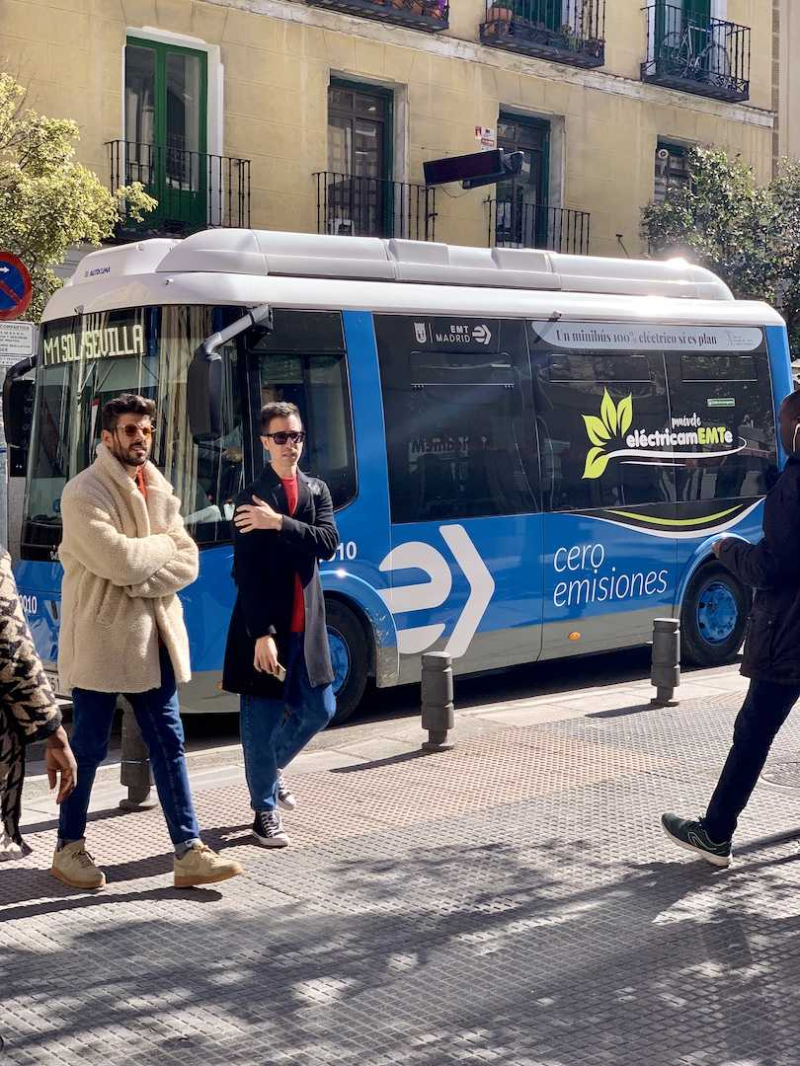

In [4]:
print("Capturing one frame... allow the camera in your browser.")
frames = get_frames(n=1)
if frames is None:
    print("Using a sample image instead.")
    camera_frame = sample_image()
else:
    camera_frame = frames[0]

print("Frame shape (height, width, channels):", camera_frame.shape)
show(camera_frame)

In [5]:
def detect_moving_objects(frames, min_area=1500):
    '''Run the full contour pipeline on a list of frames.
    Returns a list of (annotated_frame, clean_mask, count).'''
    background_detector = cv2.createBackgroundSubtractorMOG2(
        history=500, varThreshold=50, detectShadows=True
    )
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    results = []

    for frame in frames:
        mask = background_detector.apply(frame)
        _, binary = cv2.threshold(mask, 200, 255, cv2.THRESH_BINARY)
        clean_mask = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
        clean_mask = cv2.dilate(clean_mask, kernel, iterations=2)

        contours, _ = cv2.findContours(
            clean_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )

        annotated = frame.copy()
        count = 0
        for contour in contours:
            if cv2.contourArea(contour) < min_area:   # area filter
                continue
            count += 1
            x, y, w, h = cv2.boundingRect(contour)
            cv2.rectangle(annotated, (x, y), (x + w, y + h), (0, 255, 0), 3)
            cv2.putText(annotated, f"Object {count}", (x, max(y - 10, 20)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

        cv2.putText(annotated, f"Moving objects: {count}", (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 3)
        results.append((annotated, clean_mask, count))
    return results

print("Contour detector ready")

Contour detector ready


Recording ~6 seconds. Stay still for 2 seconds, then move in front of the camera...


<IPython.core.display.Javascript object>

Frames with moving objects: 19 of 28


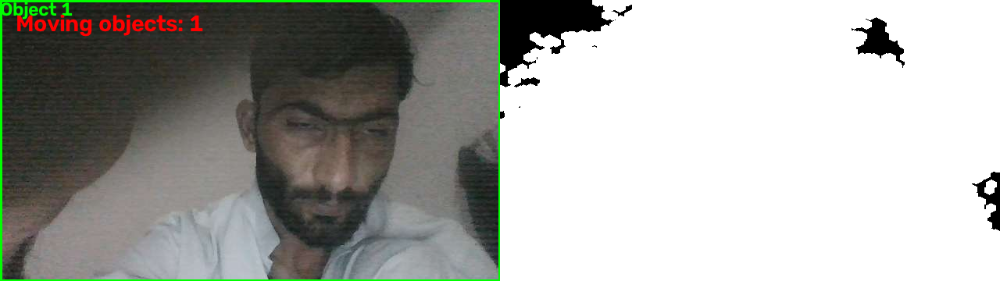

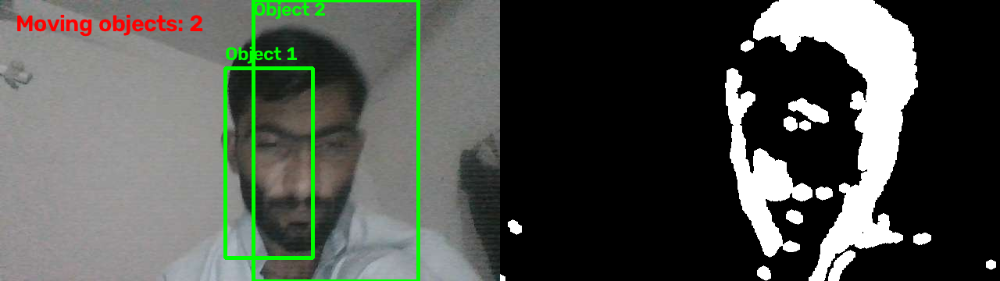

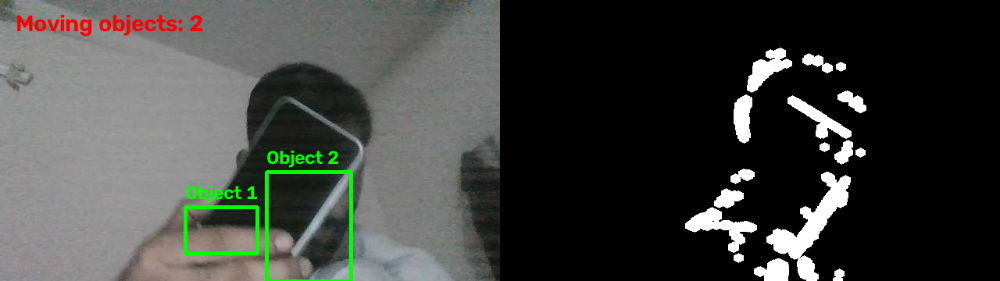

In [6]:
print("Recording ~6 seconds. Stay still for 2 seconds, then move in front of the camera...")
motion_frames = get_frames(n=40, delay_ms=150, quality=0.6)
if motion_frames is None:
    print("Using synthetic frames instead.")
    motion_frames = synthetic_frames(40)

motion_results = detect_moving_objects(motion_frames)


detected = [r for r in motion_results[12:] if r[2] > 0]
print(f"Frames with moving objects: {len(detected)} of {len(motion_results) - 12}")

if not detected:
    print("No motion detected. Re-run the cell and move more clearly after 2 seconds.")
else:
    step = max(1, len(detected) // 3)
    for annotated, clean_mask, count in detected[::step][:3]:
        mask_bgr = cv2.cvtColor(clean_mask, cv2.COLOR_GRAY2BGR)
        show(np.hstack([annotated, mask_bgr]), max_width=1000)

In [7]:
def load_yolo():
    '''Load YOLO26 nano; fall back to YOLO11 nano if YOLO26 is not available.'''
    for name in ("yolo26n.pt", "yolo11n.pt"):
        try:
            m = YOLO(name)
            print("YOLO model loaded:", name)
            return m
        except Exception as e:
            print(f"Could not load {name}: {e}")
    raise RuntimeError("No YOLO model could be loaded. Check your internet connection.")

model = load_yolo()

YOLO model loaded: yolo26n.pt


Detection completed


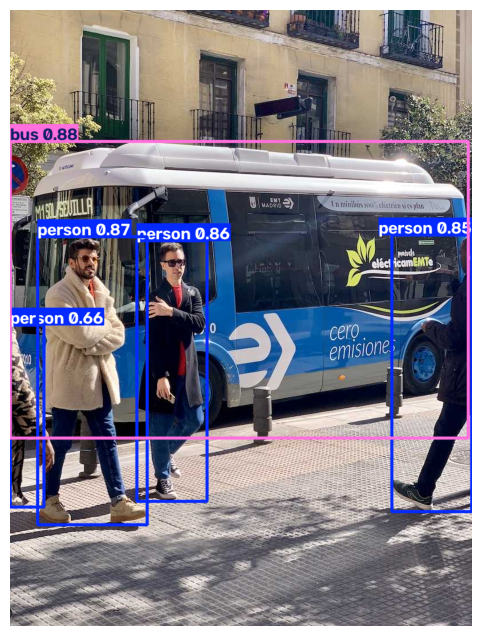

In [8]:
image_path = str(ASSETS / "bus.jpg")

results = model.predict(source=image_path, conf=0.50, verbose=False)
print("Detection completed")

result_image = results[0].plot()
result_rgb = cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(result_rgb)
plt.axis("off")
plt.show()

In [9]:
for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = results[0].names[class_id]
    confidence = float(box.conf[0])
    x1, y1, x2, y2 = [int(v) for v in box.xyxy[0]]
    print(f"{class_name:12s} confidence={confidence:.2f}  box=({x1}, {y1}, {x2}, {y2})")

bus          confidence=0.88  box=(0, 230, 803, 750)
person       confidence=0.87  box=(48, 397, 240, 902)
person       confidence=0.86  box=(222, 404, 345, 861)
person       confidence=0.85  box=(669, 394, 809, 879)
person       confidence=0.66  box=(0, 552, 59, 871)


Capturing one frame. Hold up objects like a bottle, book or phone...


<IPython.core.display.Javascript object>

Objects detected: 1


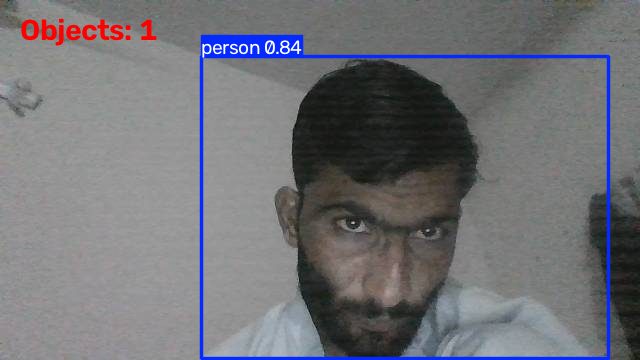

In [10]:
def detect_with_yolo(frame, conf=0.50):
    results = model.predict(source=frame, conf=conf, verbose=False)
    detected_frame = results[0].plot()
    number_of_objects = len(results[0].boxes)
    cv2.putText(detected_frame, f"Objects: {number_of_objects}", (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 3)
    return detected_frame, number_of_objects

print("Capturing one frame. Hold up objects like a bottle, book or phone...")
frames = get_frames(n=1)
frame = frames[0] if frames else sample_image()
if frames is None:
    print("Using a sample image instead.")

detected_frame, count = detect_with_yolo(frame)
print("Objects detected:", count)
show(detected_frame)

Capturing 6 frames (about 3 seconds). Move objects around...


<IPython.core.display.Javascript object>

Frame 1: 2 object(s)


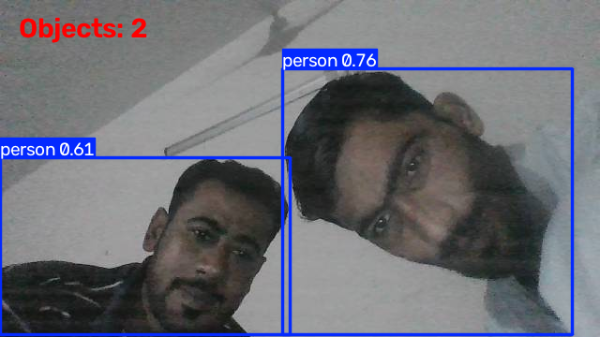

Frame 2: 2 object(s)


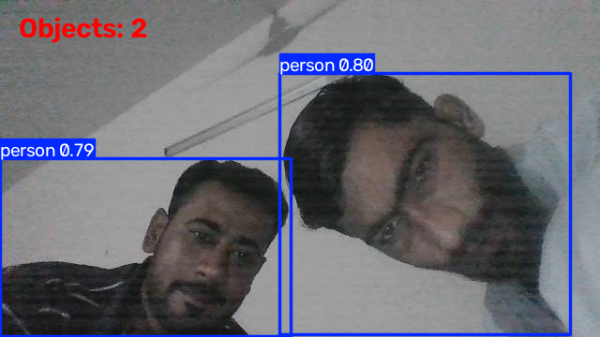

Frame 3: 2 object(s)


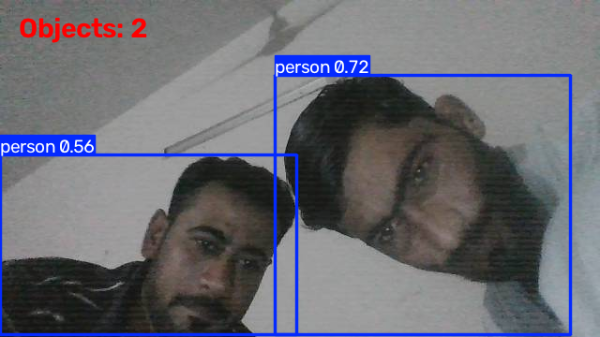

Frame 4: 2 object(s)


In [ ]:
print("Capturing 6 frames (about 3 seconds). Move objects around...")
live_frames = get_frames(n=6, delay_ms=500, quality=0.7)
if live_frames is None:
    print("Using sample images instead.")
    live_frames = [sample_image()] * 3

start = time.time()
for i, f in enumerate(live_frames, 1):
    detected_frame, count = detect_with_yolo(f)
    print(f"Frame {i}: {count} object(s)")
    show(detected_frame, max_width=600)
elapsed = time.time() - start
print(f"Processed {len(live_frames)} frames in {elapsed:.1f}s ({len(live_frames)/elapsed:.1f} frames/second)")